# Combined VisionSpeak

This notebook provides one webcam interface for the custom eight-word lip reader and the 18-label YOLO gesture detector. The two models run in isolated Python environments so MediaPipe and Ultralytics never load competing OpenCV wheels in the same process.

## Controls

- **Space** — in lip mode, start a two-second countdown and record one three-second word.
- **M** — release the webcam and switch to the other prediction mode.
- **Q** — release the webcam and finish the session.

The webcam session does not record audio or save video. Sections 7-9 also test existing MP4 recordings and static gesture images offline. Select the **VisionSpeak Lip** kernel created from `requirements.txt`; the YOLO worker is launched automatically from `.venv-yolo`.

## 1. Load the project launcher

Run this notebook from anywhere inside the repository. The following cell locates the project root and imports the standard-library launcher.

In [10]:
from pathlib import Path
import os
import sys

from IPython.display import Markdown, display


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'requirements.txt').is_file() and (candidate / 'inference').is_dir():
            return candidate
    raise FileNotFoundError('Could not find the VisionSpeak project root.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from inference.launcher import (
    CombinedConfig,
    ConfigurationError,
    run_combined_session,
    validate_combined_config,
)

print(f'Project root: {PROJECT_ROOT}')
print(f'Notebook kernel: {sys.executable}')

Project root: C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak
Notebook kernel: c:\Users\Valente\anaconda3\envs\NUS\python.exe


## 2. Install environments (first run)

The two workers must stay in separate environments because MediaPipe and Ultralytics depend on different OpenCV wheels. This cell is safe to run every time: it probes imports first and only installs what is missing.

- **Lip environment** — if this kernel cannot import `cv2`, `mediapipe`, or `torch`, `requirements.txt` is pip-installed into the running interpreter. Restart the kernel afterwards so the new packages load.
- **YOLO environment** — `.venv-yolo` is created when missing and `requirements-yolo.txt` is installed into it only when its imports are unavailable.

Set `FORCE_REINSTALL = True` to recreate or repopulate either environment from scratch.

In [11]:
from inference.environment_setup import (
    setup_lip_environment,
    setup_worker_environment,
)

INSTALL_LIP = True
INSTALL_YOLO = True
FORCE_REINSTALL = False

if INSTALL_LIP:
    lip_installed = setup_lip_environment(
        PROJECT_ROOT / 'requirements.txt',
        force=FORCE_REINSTALL,
    )
    if lip_installed:
        print('Lip environment: packages installed. Restart the kernel, then rerun this notebook from the top.')
    else:
        print('Lip environment: ready.')
else:
    print('Lip environment: skipped (INSTALL_LIP = False).')

if INSTALL_YOLO:
    yolo_python, yolo_installed = setup_worker_environment(
        PROJECT_ROOT / '.venv-yolo',
        PROJECT_ROOT / 'requirements-yolo.txt',
        force=FORCE_REINSTALL,
    )
    status = 'installed' if yolo_installed else 'ready'
    print(f'YOLO worker: {status} at {yolo_python}')
else:
    print('YOLO worker: skipped (INSTALL_YOLO = False).')

Lip environment: ready.
YOLO worker: ready at C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\.venv-yolo\Scripts\python.exe


## 3. Configure the session

Leave the interpreter values as `None` for automatic `.venv` and `.venv-yolo` discovery. Set an absolute path only when your environments use different names.

In [12]:
INITIAL_MODE = 'lip'  # 'lip' or 'gesture'
CAMERA_INDEX = 0
LIP_PYTHON = None
GESTURE_PYTHON = None
LIP_DEVICE = 'auto'  # auto, cpu, cuda, or mps
GESTURE_DEVICE = None  # None lets Ultralytics choose

CONFIG = CombinedConfig(
    project_root=PROJECT_ROOT,
    initial_mode=INITIAL_MODE,
    camera_index=CAMERA_INDEX,
    lip_python=LIP_PYTHON,
    gesture_python=GESTURE_PYTHON,
    lip_checkpoint='checkpoints/retrain/word_transformer_attention_ep200.pt',
    gesture_checkpoint='checkpoints/retrain/yolov8n50.pt',
    countdown_seconds=2.0,
    capture_seconds=3.0,
    min_frames=30,
    min_detection_rate=0.75,
    max_frames=90,
    gesture_confidence=0.5,
    lip_device=LIP_DEVICE,
    gesture_device=GESTURE_DEVICE,
)
CONFIG

CombinedConfig(project_root=WindowsPath('C:/Users/Valente/Desktop/School/Masters/Pattern Recognition System/Practice Module/VisionSpeak'), initial_mode='lip', camera_index=0, lip_python=None, gesture_python=None, lip_checkpoint='checkpoints/retrain/word_transformer_attention_ep200.pt', gesture_checkpoint='checkpoints/retrain/yolov8n50.pt', countdown_seconds=2.0, capture_seconds=3.0, min_frames=30, min_detection_rate=0.75, max_frames=90, gesture_confidence=0.5, lip_device='auto', gesture_device=None)

## 4. Validate environments and checkpoints

This check runs imports in each isolated interpreter without opening the webcam. Any missing dependency or path is reported before the session starts.

In [13]:
try:
    RESOLVED_CONFIG = validate_combined_config(CONFIG, check_imports=True)
except ConfigurationError as error:
    display(Markdown(f'### ❌ Configuration error\n\n```text\n{error}\n```'))
    raise
else:
    display(Markdown('### ✅ Both worker environments are ready'))
    print(f'Lip Python:     {RESOLVED_CONFIG.lip_python}')
    print(f'Gesture Python: {RESOLVED_CONFIG.gesture_python}')
    print(f'Lip checkpoint: {RESOLVED_CONFIG.lip_checkpoint.name}')
    print(f'Gesture backend: {RESOLVED_CONFIG.gesture_backend}')
    print(f'Gesture checkpoint: {RESOLVED_CONFIG.gesture_checkpoint.name}')

### ✅ Both worker environments are ready

Lip Python:     c:\Users\Valente\anaconda3\envs\NUS\python.exe
Gesture Python: C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\.venv-yolo\Scripts\python.exe
Lip checkpoint: word_transformer_attention_ep200.pt
Gesture backend: yolo
Gesture checkpoint: yolov8n50.pt


## 5. Start the combined webcam session

An OpenCV window will open. Keep that window focused when using Space, M, or Q. Mode switches briefly close the window while the current worker releases the camera and the other model loads.

In [14]:
SESSION_SUMMARY = run_combined_session(CONFIG)
print('Combined session finished.')

Starting lip mode. Press M to switch or Q to quit.
Combined session finished.


## 6. Session summary

In [15]:
if 'SESSION_SUMMARY' not in globals():
    raise RuntimeError('Run the combined webcam session cell first.')

status = '✅ Completed' if SESSION_SUMMARY.completed else '❌ Stopped with an error'
display(Markdown(f'### {status}'))
print(f'Initial mode: {SESSION_SUMMARY.initial_mode}')
print(f'Mode switches: {SESSION_SUMMARY.switch_count}')
for number, event in enumerate(SESSION_SUMMARY.events, start=1):
    print(
        f'{number}. {event.mode}: {event.action} '
        f'(exit {event.return_code}, {event.elapsed_seconds:.1f}s)'
    )
if SESSION_SUMMARY.error:
    display(Markdown(f'**Error:** `{SESSION_SUMMARY.error}`'))

### ✅ Completed

Initial mode: lip
Mode switches: 0
1. lip: quit (exit 0, 15.6s)


## 7. Offline testing setup

Run sections 1 and 3 first. These tests use the current `CONFIG` checkpoints, devices, quality gates and confidence threshold, without opening the webcam. The worker runs in the same isolated interpreter selected for live inference. Environment installation and the webcam session are not required if dependencies are already installed.

`TEST_LIMIT = None` evaluates all files. Set it to a small positive number before running the test cells for a quick check. No dataset files or checkpoints are modified.

In [16]:
import json
import subprocess
import tempfile
import pandas as pd
import matplotlib.pyplot as plt

LIP_TEST_DIR = PROJECT_ROOT / 'data/custom_words/raw/speaker_test_samples1'
GESTURE_TEST_DIR = PROJECT_ROOT / 'models/Lawrence/test_selfie/images'
TEST_LIMIT = None  # Set to e.g. 2 for a quick smoke test; None tests all files.


def run_offline_worker(mode, directory, limit=TEST_LIMIT):
    # Resolve CONFIG afresh so checkpoint edits never reuse stale validation.
    resolved = validate_combined_config(CONFIG, check_imports=False)
    files = sorted(path for path in directory.rglob('*') if path.is_file() and
                   path.suffix.lower() in ({'.mp4'} if mode == 'lip' else
                   {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}))
    if limit is not None:
        if limit < 1:
            raise ValueError('TEST_LIMIT must be positive or None.')
        files = files[:limit]
    if not files:
        raise FileNotFoundError(f'No {mode} test files found in {directory}')
    settings = dict(mode=mode, files=[str(p) for p in files],
                    checkpoint=str(resolved.lip_checkpoint if mode == 'lip' else resolved.gesture_checkpoint),
                    backend=resolved.gesture_backend, max_frames=resolved.max_frames,
                    min_frames=resolved.min_frames, min_detection_rate=resolved.min_detection_rate,
                    confidence=resolved.gesture_confidence,
                    device=resolved.lip_device if mode == 'lip' else resolved.gesture_device)
    interpreter = resolved.lip_python if mode == 'lip' else resolved.gesture_python
    print(f'Testing {len(files)} files | {settings["checkpoint"]} | {interpreter}')
    with tempfile.TemporaryDirectory(prefix='visionspeak-test-') as temporary:
        request = Path(temporary) / 'request.json'
        response = Path(temporary) / 'results.json'
        request.write_text(json.dumps(settings), encoding='utf-8')
        completed = subprocess.run(
            [str(interpreter), '-c', OFFLINE_WORKER, str(request), str(response)],
            cwd=PROJECT_ROOT, capture_output=True, text=True, encoding='utf-8', errors='replace')
        if completed.returncode:
            raise RuntimeError(f'Offline worker failed:\n{completed.stdout}\n{completed.stderr}')
        return pd.DataFrame(json.loads(response.read_text(encoding='utf-8')))


def show_offline_results(results, title):
    display(results)
    predicted = results['status'].eq('predicted')
    correct = predicted & results['actual'].eq(results['prediction'])
    print(f'{title}: {correct.sum()}/{len(results)} correct ({correct.mean():.1%})')
    print(f'Predicted: {predicted.sum()} | Rejected/errors: {(~predicted).sum()}')
    if predicted.any():
        print(f'Accuracy among accepted predictions: {correct.sum() / predicted.sum():.1%}')
    # Include rejected/no-detection/error outcomes rather than silently dropping them.
    matrix = pd.crosstab(results['actual'], results['prediction']).sort_index()
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(matrix.values, cmap='Blues')
    ax.set(xticks=range(len(matrix.columns)), yticks=range(len(matrix.index)),
           xticklabels=matrix.columns, yticklabels=matrix.index,
           xlabel='Predicted label / outcome', ylabel='Actual label', title=title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    for row in range(len(matrix.index)):
        for column in range(len(matrix.columns)):
            ax.text(column, row, str(matrix.iloc[row, column]), ha='center', va='center')
    fig.tight_layout()
    plt.show()

def make_playable_lip_video(path):
    """Embed a browser-compatible preview without modifying the recording."""
    import shutil
    from IPython.display import Video

    ffmpeg = shutil.which('ffmpeg')
    if ffmpeg is None:
        try:
            import imageio_ffmpeg
            ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
        except ImportError as error:
            raise RuntimeError(
                'Video preview needs FFmpeg. Install FFmpeg on PATH, or run '
                '%pip install imageio-ffmpeg in this kernel, then retry.'
            ) from error
    with tempfile.TemporaryDirectory(prefix='visionspeak-preview-') as directory:
        preview = Path(directory) / 'preview.mp4'
        command = [ffmpeg, '-hide_banner', '-loglevel', 'error', '-y',
                   '-i', str(path), '-map', '0:v:0', '-an',
                   '-vf', 'pad=ceil(iw/2)*2:ceil(ih/2)*2',
                   '-c:v', 'libx264', '-pix_fmt', 'yuv420p',
                   '-movflags', '+faststart', str(preview)]
        completed = subprocess.run(command, capture_output=True, text=True,
                                   encoding='utf-8', errors='replace', timeout=120)
        if completed.returncode:
            raise RuntimeError(f'Could not prepare H.264 preview: {completed.stderr}')
        # Read bytes before the temporary file is deleted.
        return Video(data=preview.read_bytes(), embed=True, mimetype='video/mp4',
                     width=640, html_attributes='controls playsinline')


def show_random_test_example(results, mode, random_state=None):
    """Preview one actual tested file, including rejected/error outcomes."""
    from IPython.display import Image

    if mode not in {'lip', 'gesture'}:
        raise ValueError("mode must be 'lip' or 'gesture'.")
    if results.empty:
        print('No tested samples are available to preview.')
        return None
    sample = results.sample(n=1, random_state=random_state).iloc[0]
    print(f"File: {sample['file']}")
    print(f"Actual: {sample['actual']} | Prediction: {sample['prediction']} | "
          f"Confidence: {sample['confidence']:.1%} | Status: {sample['status']}")
    if sample.get('message'):
        print(f"Details: {sample['message']}")
    path = Path(sample['file'])
    if not path.is_file():
        print(f'Preview unavailable: file no longer exists: {path}')
        return sample
    if mode == 'lip':
        display(make_playable_lip_video(path))
    else:
        display(Image(filename=str(path), width=640))
    return sample


OFFLINE_WORKER = "import json, sys, re\nfrom pathlib import Path\nfrom contextlib import ExitStack\nimport cv2\nimport numpy as np\n\nsettings = json.loads(Path(sys.argv[1]).read_text(encoding='utf-8'))\nrows = []\nwith ExitStack() as resources:\n    if settings['mode'] == 'lip':\n        from importlib import import_module\n        from inference.lip_worker import LipPredictor, TimestampClock\n        from processing.mouth_cropper import MouthCropper\n        extract = import_module('evaluation.lip-reading.evaluate_custom_words').extract_mp4_mouth_frames\n        predictor = LipPredictor(Path(settings['checkpoint']), settings['device'])\n        cropper = resources.enter_context(MouthCropper(target_size=(100, 50)))\n        clock = TimestampClock()\n    elif settings['backend'] == 'yolo':\n        from ultralytics import YOLO\n        model = YOLO(settings['checkpoint'])\n    else:\n        import torch\n        from models.SX.inference import choose_device, load_sx_checkpoint\n        from models.SX.features import create_landmarker, extract_rgb\n        device = choose_device(settings['device'] or 'auto')\n        model, labels, config = load_sx_checkpoint(settings['checkpoint'], device)\n        index_to_label = {index: label for label, index in labels.items()}\n        hands = resources.enter_context(create_landmarker('hand'))\n        pose = resources.enter_context(create_landmarker('pose')) if config.use_body_pose else None\n\n    for filename in settings['files']:\n        path = Path(filename)\n        actual = path.parent.name.lower() if settings['mode'] == 'lip' else re.sub(r'_\\d+$', '', path.stem).lower()\n        row = dict(file=filename, actual=actual, prediction='<error>', confidence=0.0, status='error', message='')\n        try:\n            if settings['mode'] == 'lip':\n                cropper.reset_tracking()\n                frames, rate, reason = extract(path, cropper, clock,\n                    min_frames=settings['min_frames'], min_detection_rate=settings['min_detection_rate'])\n                row['detection_rate'] = rate\n                if frames is None:\n                    row.update(prediction='<rejected>', status='rejected', message=reason)\n                else:\n                    prediction = predictor.predict(frames, max_frames=settings['max_frames'])\n                    row.update(prediction=prediction.label.lower(), confidence=prediction.confidence, status='predicted')\n            else:\n                image = cv2.imread(str(path))\n                if image is None:\n                    raise ValueError('Could not decode image.')\n                if settings['backend'] == 'yolo':\n                    options = dict(conf=settings['confidence'], imgsz=640, verbose=False)\n                    if settings['device'] is not None:\n                        options['device'] = settings['device']\n                    result = model.predict(source=image, **options)[0]\n                    if result.boxes is None or len(result.boxes) == 0:\n                        row.update(prediction='<no detection>', status='rejected', message='No box above confidence threshold.')\n                    else:\n                        best = int(result.boxes.conf.argmax())\n                        row.update(prediction=str(result.names[int(result.boxes.cls[best])]).lower(),\n                                   confidence=float(result.boxes.conf[best]), status='predicted')\n                else:\n                    vector, detected = extract_rgb(cv2.cvtColor(image, cv2.COLOR_BGR2RGB),\n                        two_hands=config.two_hands, use_body_pose=config.use_body_pose, hands=hands, pose=pose)\n                    if not detected:\n                        row.update(prediction='<no detection>', status='rejected', message='No hand landmarks detected.')\n                    else:\n                        # A still image supplies no motion: repeat its landmarks independently for each image.\n                        inputs = torch.from_numpy(np.repeat(vector[None, :], config.window_size, axis=0)).unsqueeze(0).to(device)\n                        with torch.inference_mode():\n                            confidence, index = model(inputs).softmax(dim=1).max(dim=1)\n                        score = confidence.item()\n                        row.update(confidence=score)\n                        if score < settings['confidence']:\n                            row.update(prediction='<low confidence>', status='rejected')\n                        else:\n                            row.update(prediction=index_to_label[index.item()].lower(), status='predicted')\n        except Exception as error:\n            row.update(message=str(error))\n        rows.append(row)\nPath(sys.argv[2]).write_text(json.dumps(rows), encoding='utf-8')\n"


## 8. Lip-reading MP4 testing

Reads `data/custom_words/raw/speaker_test_samples1/<word>/*.mp4`. The parent folder supplies the true label. Each full video uses live mouth cropping, grayscale conversion, quality checks and checkpoint-specific inference; `CONFIG.max_frames` controls subsampling/padding. Countdown and capture duration apply only to the webcam and do not trim these recordings.

Testing 160 files | C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\checkpoints\retrain\word_transformer_attention_ep200.pt | c:\Users\Valente\anaconda3\envs\NUS\python.exe


,file,actual,prediction,confidence,status,message,detection_rate
0,C:\Users\Valente\Desktop\School\Masters\Patter...,bad,bad,1.000000,predicted,,1.0
1,C:\Users\Valente\Desktop\School\Masters\Patter...,bad,bad,1.000000,predicted,,1.0
2,C:\Users\Valente\Desktop\School\Masters\Patter...,bad,bad,1.000000,predicted,,1.0
3,C:\Users\Valente\Desktop\School\Masters\Patter...,bad,bad,1.000000,predicted,,1.0
4,C:\Users\Valente\Desktop\School\Masters\Patter...,bad,bad,1.000000,predicted,,1.0
...,...,...,...,...,...,...,...
155,C:\Users\Valente\Desktop\School\Masters\Patter...,yes,thanks,0.999983,predicted,,1.0
156,C:\Users\Valente\Desktop\School\Masters\Patter...,yes,thanks,0.999920,predicted,,1.0
157,C:\Users\Valente\Desktop\School\Masters\Patter...,yes,thanks,0.999829,predicted,,1.0
158,C:\Users\Valente\Desktop\School\Masters\Patter...,yes,thanks,0.999956,predicted,,1.0


Lip reading: speaker_test_samples1: 126/160 correct (78.8%)
Predicted: 160 | Rejected/errors: 0
Accuracy among accepted predictions: 78.8%


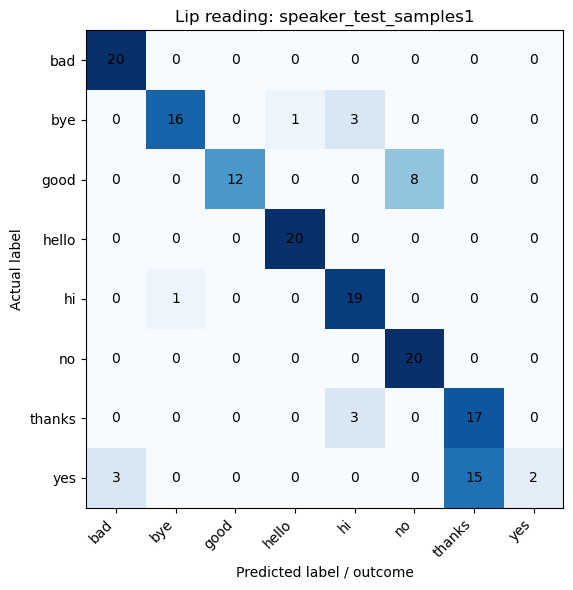

In [19]:
LIP_TEST_RESULTS = run_offline_worker('lip', LIP_TEST_DIR, limit=TEST_LIMIT)
show_offline_results(LIP_TEST_RESULTS, 'Lip reading: speaker_test_samples1')

In [ ]:
LIP_TEST_EXAMPLE = show_random_test_example(LIP_TEST_RESULTS, 'lip')

## 9. Hand-gesture static-image testing

Reads `models/Lawrence/test_selfie/images`. Filenames such as `hello_01.jpg` supply the true label (`hello`). Checkpoint metadata selects YOLO in its isolated environment, or MediaPipe + LSTM/Transformer in the lip environment. SX Transformer inputs repeat each still image's landmarks to the saved window length; this tests static pose recognition, not temporal motion. Rejections and errors count as incorrect in overall accuracy and remain visible in the confusion matrix.

Testing 160 files | C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\checkpoints\retrain\yolov8n50.pt | C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\.venv-yolo\Scripts\python.exe


,file,actual,prediction,confidence,status,message
0,C:\Users\Valente\Desktop\School\Masters\Patter...,get,get,0.778952,predicted,
1,C:\Users\Valente\Desktop\School\Masters\Patter...,get,get,0.648192,predicted,
2,C:\Users\Valente\Desktop\School\Masters\Patter...,get,get,0.749607,predicted,
3,C:\Users\Valente\Desktop\School\Masters\Patter...,get,get,0.645128,predicted,
4,C:\Users\Valente\Desktop\School\Masters\Patter...,get,get,0.991793,predicted,
...,...,...,...,...,...,...
155,C:\Users\Valente\Desktop\School\Masters\Patter...,you,you,0.892288,predicted,
156,C:\Users\Valente\Desktop\School\Masters\Patter...,you,i,0.699633,predicted,
157,C:\Users\Valente\Desktop\School\Masters\Patter...,you,you,0.792151,predicted,
158,C:\Users\Valente\Desktop\School\Masters\Patter...,you,you,0.984146,predicted,


Hand gesture: test_selfie images: 153/160 correct (95.6%)
Predicted: 158 | Rejected/errors: 2
Accuracy among accepted predictions: 96.8%


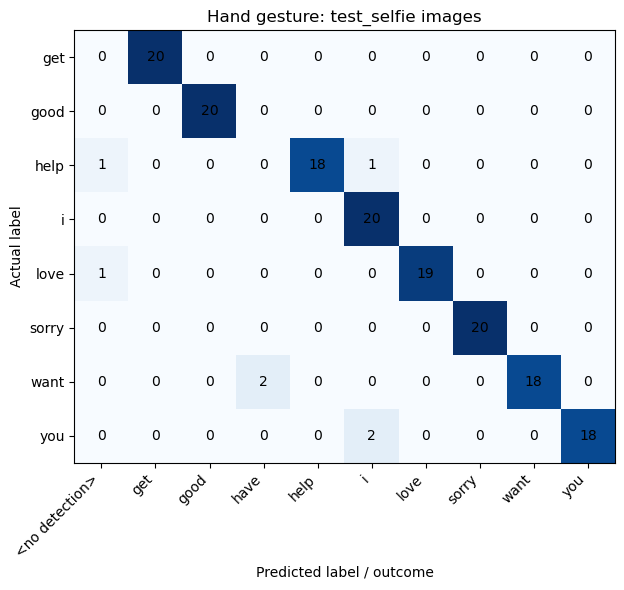

In [20]:
GESTURE_TEST_RESULTS = run_offline_worker('gesture', GESTURE_TEST_DIR, limit=TEST_LIMIT)
show_offline_results(GESTURE_TEST_RESULTS, 'Hand gesture: test_selfie images')

In [ ]:
GESTURE_TEST_EXAMPLE = show_random_test_example(GESTURE_TEST_RESULTS, 'gesture')